<a href="https://colab.research.google.com/github/divyanshutries/wine-quality-eda/blob/main/Wine_Quality_EDA_DivyanshuMishra.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Wine Quality — Exploratory Data Analysis (EDA)

* **Student Name:** [Divyanshu Mishra]
* **Email Address:** [B26EE024@iitbhilai.ac.in]
* **Dataset:** UCI Machine Learning Repository — Wine Quality Dataset (Cortez et al., 2009)

## Project Overview
This notebook presents a comprehensive Exploratory Data Analysis (EDA) of Portuguese *Vinho Verde* red (1,599 samples) and white (4,898 samples) wines across 11 physicochemical laboratory measurements and 1 sensory quality score (0–10 scale). Through data cleaning, univariate distribution profiling, comparative group analysis, correlation modeling, and statistical hypothesis testing, this study investigates the chemical drivers of sensory wine quality and differences between wine varieties.

In [4]:
# Import essential data manipulation, numerical, and visualization libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Configure clean visual styling for all charts in the notebook
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (10, 5)


def inspect_dataframe(df: pd.DataFrame, name: str) -> None:
    """
    Display structural metadata, dimensions, data types, and sample records for a DataFrame.

    Parameters
    ----------
    df : pd.DataFrame
        The dataset to inspect.
    name : str
        Descriptive label for printing headers.
    """
    print(f"=== {name} Dataset Overview ===")
    print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns\n")
    df.info(memory_usage="deep")
    print(f"\nFirst 10 records of {name}:")
    display(df.head(10))
    print(f"\nLast 10 records of {name}:")
    display(df.tail(10))


def summarize_missing_and_duplicates(df: pd.DataFrame, name: str) -> pd.DataFrame:
    """
    Calculate missing value counts/percentages and report duplicate row statistics.

    Parameters
    ----------
    df : pd.DataFrame
        The dataset to audit.
    name : str
        Descriptive label for the dataset.

    Returns
    -------
    pd.DataFrame
        Summary table of missing values per column.
    """
    missing_count = df.isnull().sum()
    missing_pct = (missing_count / len(df) * 100).round(2)
    dup_count = df.duplicated().sum()
    dup_pct = round(dup_count / len(df) * 100, 2)

    print(f"--- {name}: Duplicate Rows = {dup_count} ({dup_pct}%) ---")
    return pd.DataFrame({"Missing_Count": missing_count, "Missing_Pct": missing_pct})


# Q1: Load red and white wine datasets directly from UCI (semicolon-separated)

red_df = pd.read_csv("winequality-red.csv", sep=";")
white_df = pd.read_csv("winequality-white.csv", sep=";")

# Q1 & Q2: Inspect first/last 10 rows, dimensions, dtypes, and memory usage
inspect_dataframe(red_df, "Red Wine")
inspect_dataframe(white_df, "White Wine")

# Q3: Combine datasets and create categorical 'wine_type' column
red_copy = red_df.copy()
red_copy["wine_type"] = "red"

white_copy = white_df.copy()
white_copy["wine_type"] = "white"

wine_df = pd.concat([red_copy, white_copy], ignore_index=True)
wine_df["wine_type"] = wine_df["wine_type"].astype("category")
print(f"\nCombined Dataset Shape: {wine_df.shape}")

# Q4 & Q5: Audit missing values and duplicate observations
display(summarize_missing_and_duplicates(red_df, "Red Wine"))
display(summarize_missing_and_duplicates(white_df, "White Wine"))

# Q6: Compare descriptive statistics (min, max, mean, median, std) across wine types
features = [col for col in red_df.columns if col != "quality"]
desc_stats = (
    wine_df.groupby("wine_type", observed=True)[features]
    .agg(["min", "max", "mean", "median", "std"])
    .T
)
print("\n=== Q6: Physicochemical Descriptive Statistics (Red vs. White) ===")
display(desc_stats)

=== Red Wine Dataset Overview ===
Shape: 1599 rows x 12 columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB

First 10 records of Red Wine:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
5,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5
6,7.9,0.60,0.06,1.6,0.069,15.0,59.0,0.9964,3.30,0.46,9.4,5
7,7.3,0.65,0.00,1.2,0.065,15.0,21.0,0.9946,3.39,0.47,10.0,7
8,7.8,0.58,0.02,2.0,0.073,9.0,18.0,0.9968,3.36,0.57,9.5,7
9,7.5,0.50,0.36,6.1,0.071,17.0,102.0,0.9978,3.35,0.80,10.5,5



Last 10 records of Red Wine:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
1589,6.6,0.725,0.20,7.8,0.073,29.0,79.0,0.99770,3.29,0.54,9.2,5
1590,6.3,0.550,0.15,1.8,0.077,26.0,35.0,0.99314,3.32,0.82,11.6,6
1591,5.4,0.740,0.09,1.7,0.089,16.0,26.0,0.99402,3.67,0.56,11.6,6
1592,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
1593,6.8,0.620,0.08,1.9,0.068,28.0,38.0,0.99651,3.42,0.82,9.5,6
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5
1598,6.0,0.310,0.47,3.6,0.067,18.0,42.0,0.99549,3.39,0.66,11.0,6


=== White Wine Dataset Overview ===
Shape: 4898 rows x 12 columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4898 entries, 0 to 4897
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         4898 non-null   float64
 1   volatile acidity      4898 non-null   float64
 2   citric acid           4898 non-null   float64
 3   residual sugar        4898 non-null   float64
 4   chlorides             4898 non-null   float64
 5   free sulfur dioxide   4898 non-null   float64
 6   total sulfur dioxide  4898 non-null   float64
 7   density               4898 non-null   float64
 8   pH                    4898 non-null   float64
 9   sulphates             4898 non-null   float64
 10  alcohol               4898 non-null   float64
 11  quality               4898 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 459.3 KB

First 10 records of White Wine:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
5,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
6,6.2,0.32,0.16,7.0,0.045,30.0,136.0,0.9949,3.18,0.47,9.6,6
7,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
8,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
9,8.1,0.22,0.43,1.5,0.044,28.0,129.0,0.9938,3.22,0.45,11.0,6


... (4 outputs left out)

--- White Wine: Duplicate Rows = 937 (19.13%) ---


,Missing_Count,Missing_Pct
fixed acidity,0,0.0
volatile acidity,0,0.0
citric acid,0,0.0
residual sugar,0,0.0
chlorides,0,0.0
free sulfur dioxide,0,0.0
total sulfur dioxide,0,0.0
density,0,0.0
pH,0,0.0
sulphates,0,0.0



=== Q6: Physicochemical Descriptive Statistics (Red vs. White) ===


wine_type                           red       white
fixed acidity        min       4.600000    3.800000
                     max      15.900000   14.200000
                     mean      8.319637    6.854788
                     median    7.900000    6.800000
                     std       1.741096    0.843868
volatile acidity     min       0.120000    0.080000
                     max       1.580000    1.100000
                     mean      0.527821    0.278241
                     median    0.520000    0.260000
                     std       0.179060    0.100795
citric acid          min       0.000000    0.000000
                     max       1.000000    1.660000
                     mean      0.270976    0.334192
                     median    0.260000    0.320000
                     std       0.194801    0.121020
residual sugar       min       0.900000    0.600000
                     max      15.500000   65.800000
                     mean      2.538806    6.391415
                     median    2.200000    5.200000
                     std       1.409928    5.072058
chlorides            min       0.012000    0.009000
                     max       0.611000    0.346000
                     mean      0.087467    0.045772
                     median    0.079000    0.043000
                     std       0.047065    0.021848
free sulfur dioxide  min       1.000000    2.000000
                     max      72.000000  289.000000
                     mean     15.874922   35.308085
                     median   14.000000   34.000000
                     std      10.460157   17.007137
total sulfur dioxide min       6.000000    9.000000
                     max     289.000000  440.000000
                     mean     46.467792  138.360657
                     median   38.000000  134.000000
                     std      32.895324   42.498065
density              min       0.990070    0.987110
                     max       1.003690    1.038980
                     mean      0.996747    0.994027
                     median    0.996750    0.993740
                     std       0.001887    0.002991
pH                   min       2.740000    2.720000
                     max       4.010000    3.820000
                     mean      3.311113    3.188267
                     median    3.310000    3.180000
                     std       0.154386    0.151001
sulphates            min       0.330000    0.220000
                     max       2.000000    1.080000
                     mean      0.658149    0.489847
                     median    0.620000    0.470000
                     std       0.169507    0.114126
alcohol              min       8.400000    8.000000
                     max      14.900000   14.200000
                     mean     10.422983   10.514267
                     median   10.200000   10.400000
                     std       1.065668    1.230621

**Q2 (Dimension Comparison):** Both datasets share the exact same 12 columns (11 continuous float64 physicochemical features and 1 integer int64 quality score), but the white wine dataset ($4,898 \times 12$) contains more than three times as many observations as the red wine dataset ($1,599 \times 12$)

**Q4 (Missing Values):** There are 0 missing values across both datasets matching that of the UCI documentation.

**Q5 (Should duplicates be removed?):** Duplicates shouldn't be removed as they could be genuine distinct wine samples or different bottles. Removing them could remove real samples that could be from the same batch especially since duplicate rows account for roughly 15% of the red dataset (240 rows) and ~19% of the white dataset (937 rows).

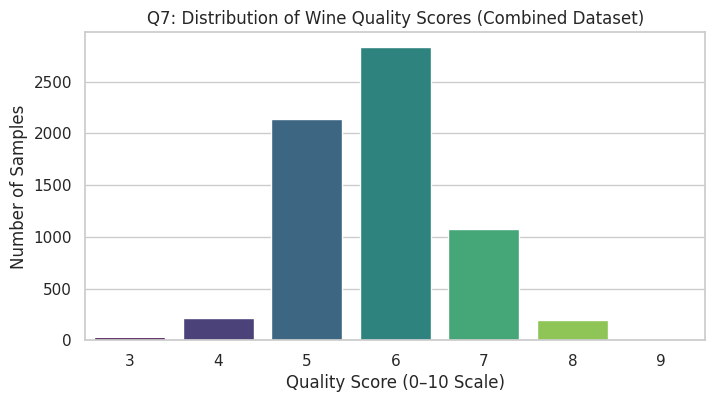

Q7 Quality Stats -> Mean: 5.82 | Median: 6.0 | Mode: 6



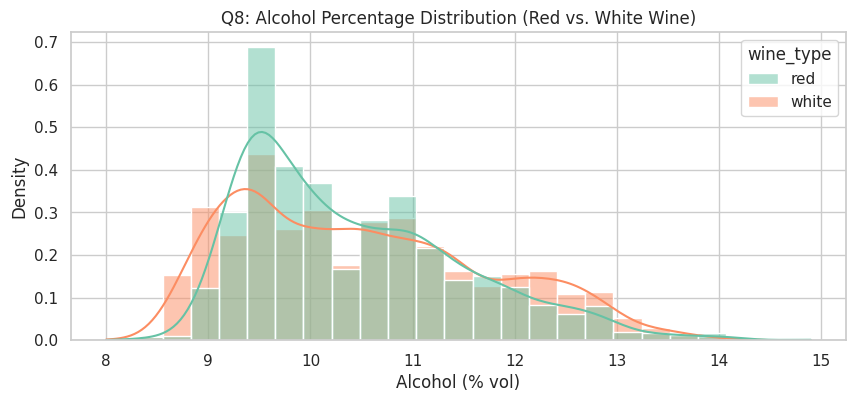

Q8 Alcohol Comparison:


,mean,median,std,min,max,range
wine_type,,,,,,
red,10.423,10.2,1.066,8.4,14.9,6.5
white,10.514,10.4,1.231,8.0,14.2,6.2


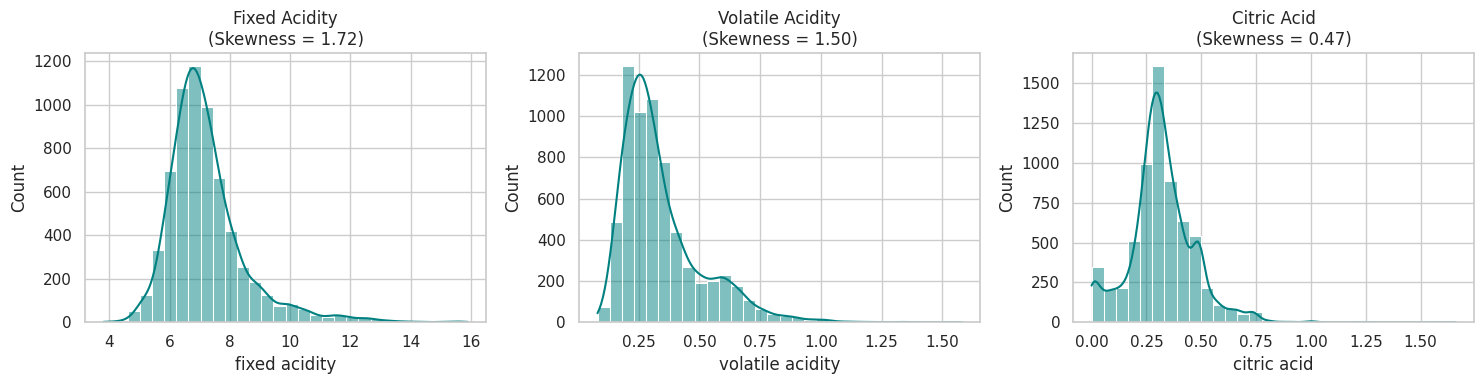

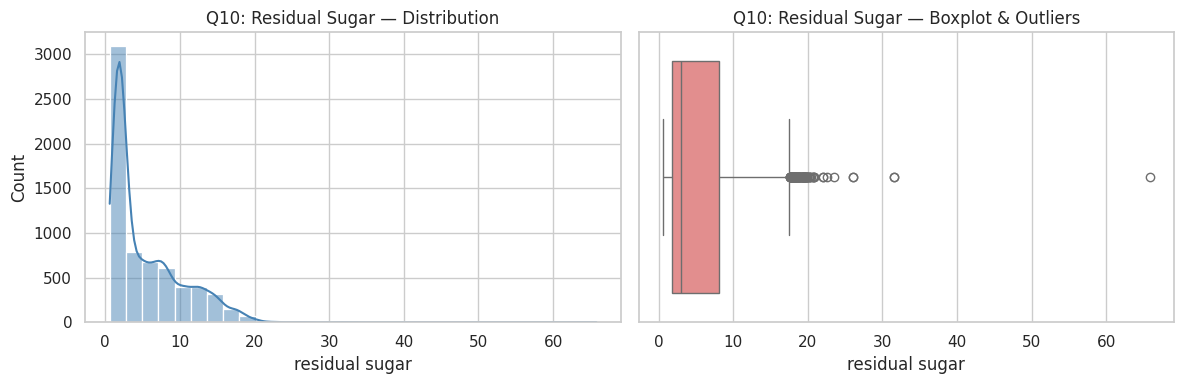

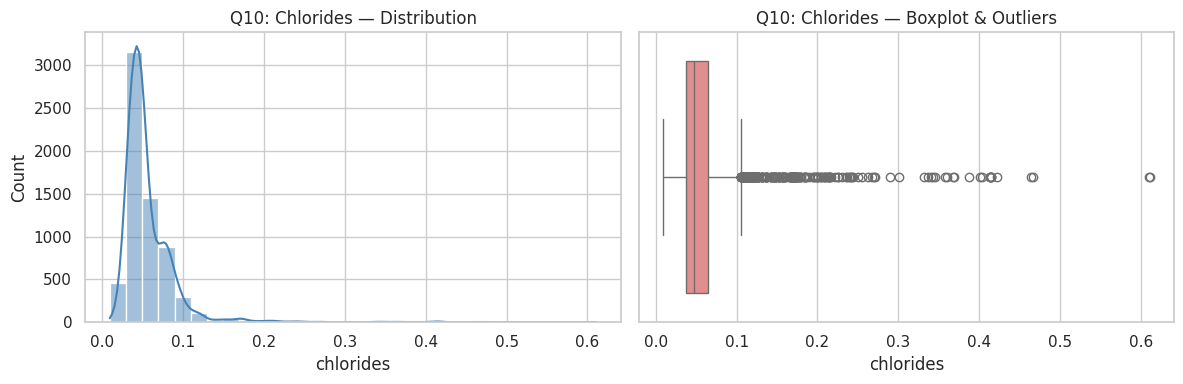

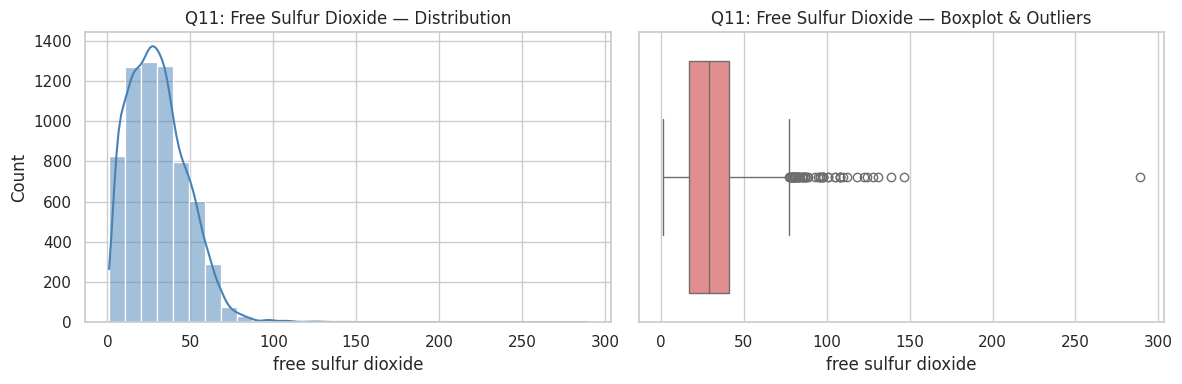

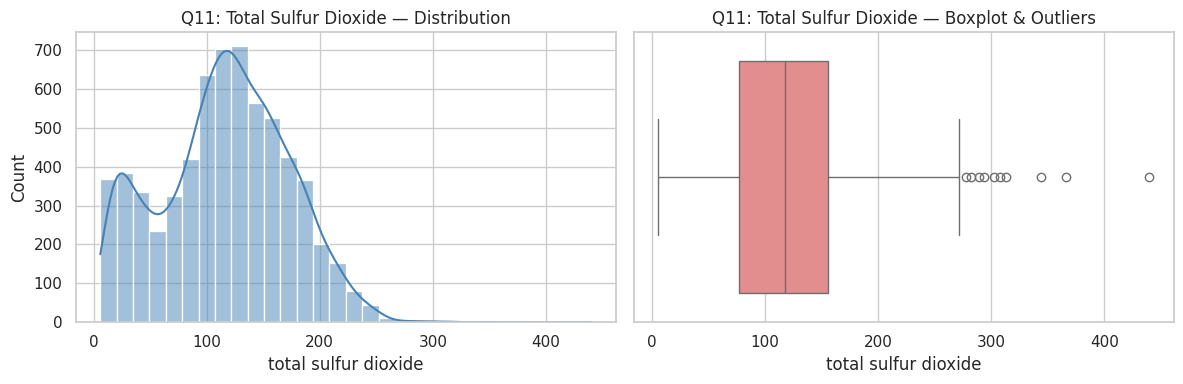

Q11 Sulfur Dioxide Summary:


,free sulfur dioxide,total sulfur dioxide
mean,30.53,115.74
median,29.00,118.00
min,1.00,6.00
max,289.00,440.00
range,288.00,434.00


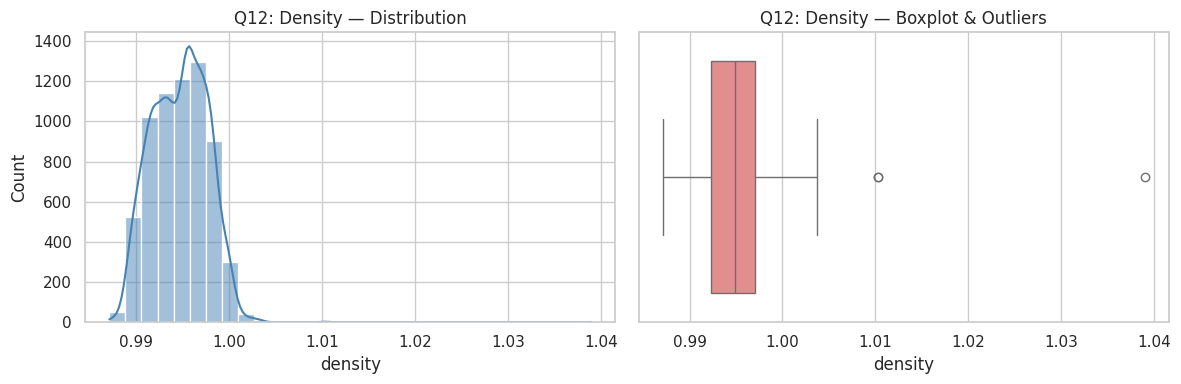

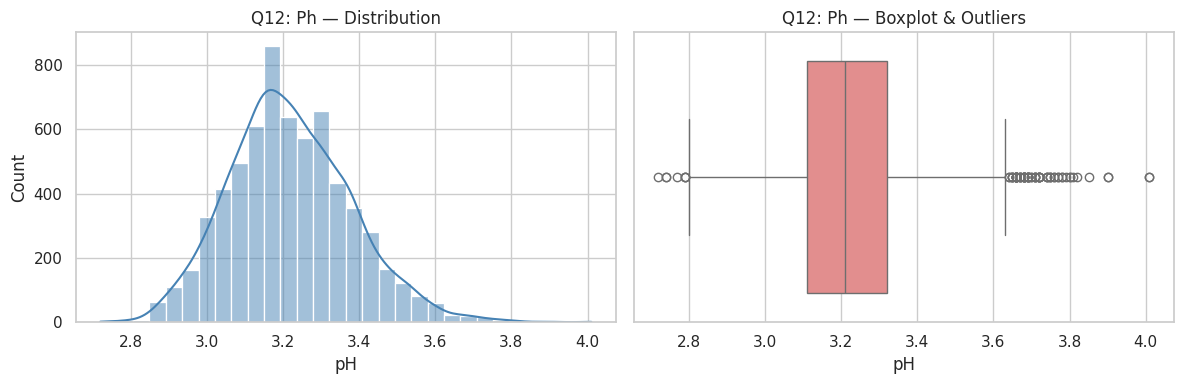

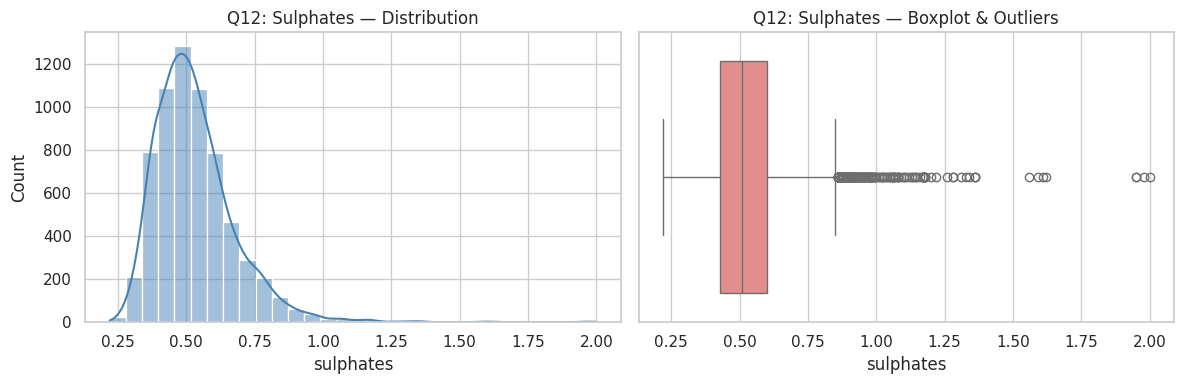

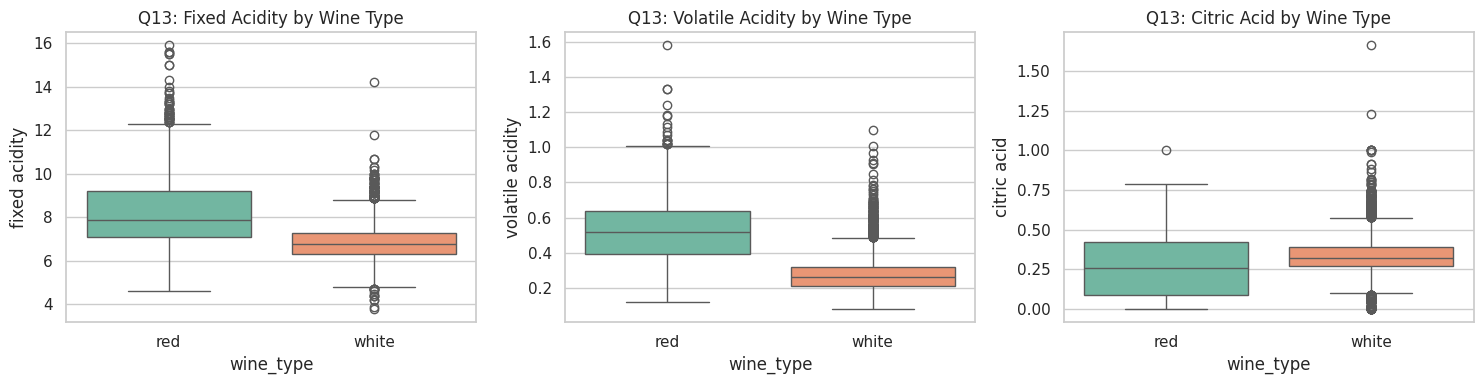

,Feature,Wine_Type,Mean,Median,IQR,Skewness
0,fixed acidity,red,8.320,7.90,2.10,0.983
1,fixed acidity,white,6.855,6.80,1.00,0.648
2,volatile acidity,red,0.528,0.52,0.25,0.672
3,volatile acidity,white,0.278,0.26,0.11,1.577
4,citric acid,red,0.271,0.26,0.33,0.318
5,citric acid,white,0.334,0.32,0.12,1.282


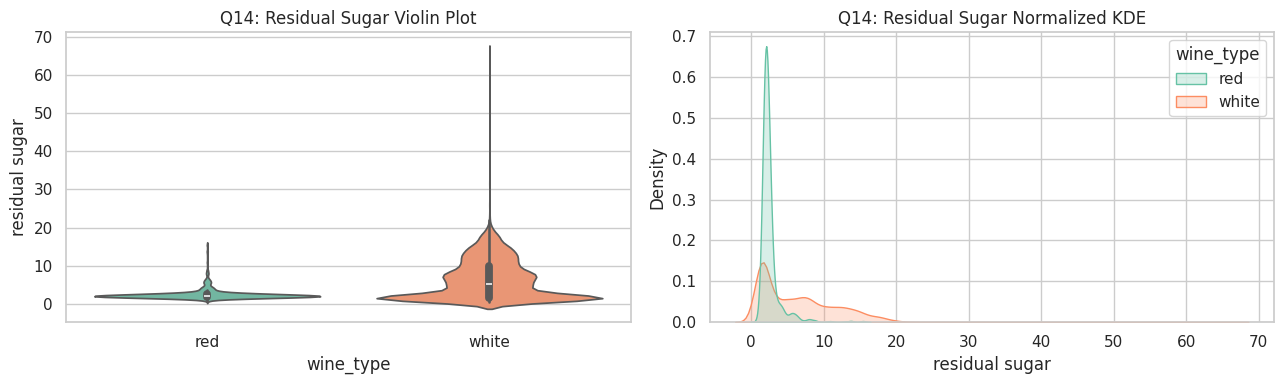

,Feature,Wine_Type,Mean,Median,IQR,Skewness
0,residual sugar,red,2.539,2.2,0.7,4.541
1,residual sugar,white,6.391,5.2,8.2,1.077


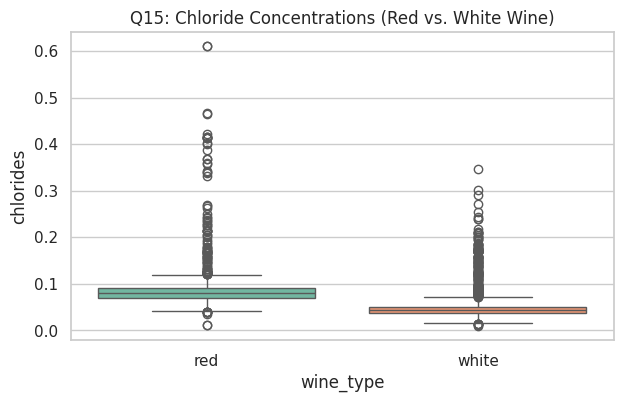

,Feature,Wine_Type,Mean,Median,IQR,Skewness
0,chlorides,red,0.087,0.079,0.020,5.680
1,chlorides,white,0.046,0.043,0.014,5.023


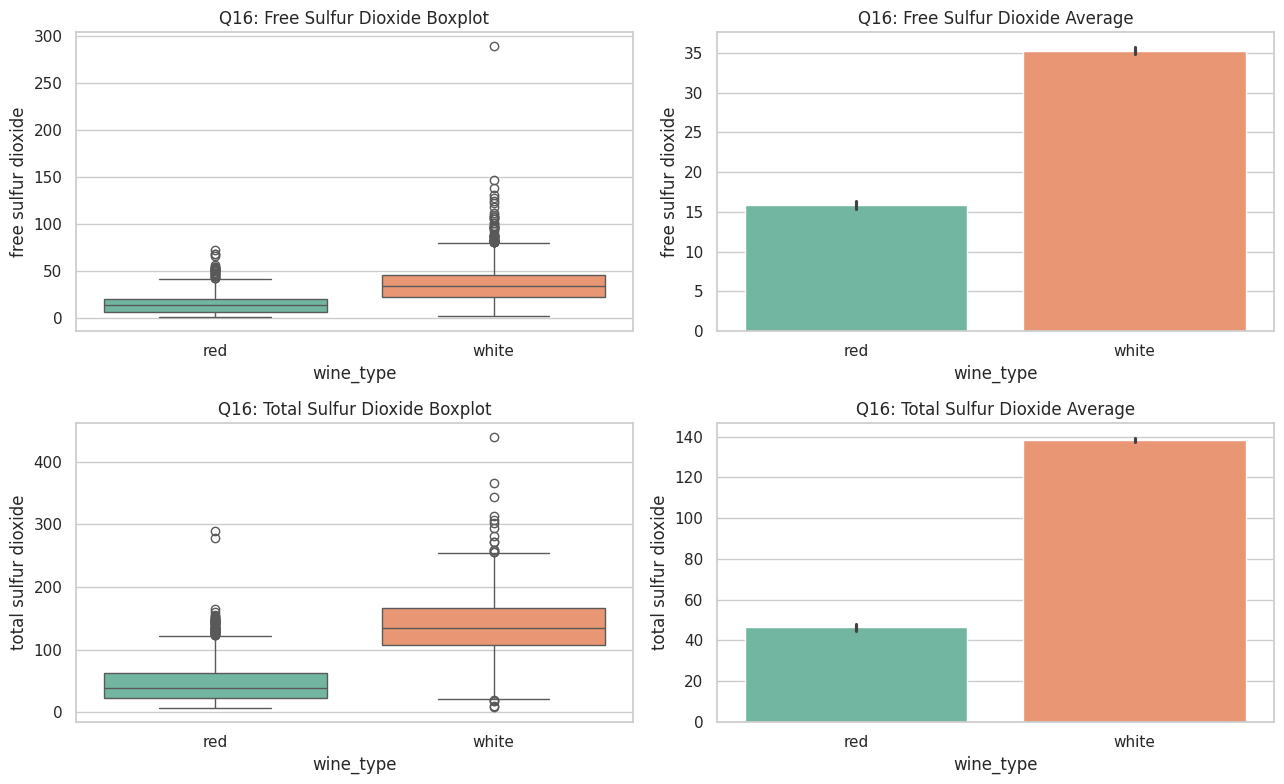

,Feature,Wine_Type,Mean,Median,IQR,Skewness
0,free sulfur dioxide,red,15.875,14.0,14.0,1.251
1,free sulfur dioxide,white,35.308,34.0,23.0,1.407
2,total sulfur dioxide,red,46.468,38.0,40.0,1.516
3,total sulfur dioxide,white,138.361,134.0,59.0,0.391


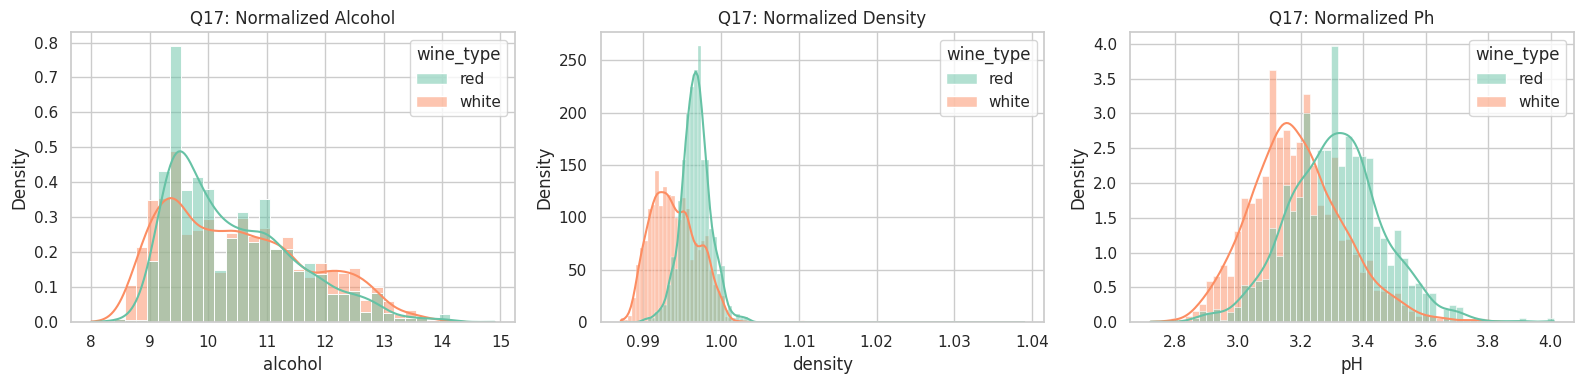

,Feature,Wine_Type,Mean,Median,IQR,Skewness
0,alcohol,red,10.423,10.200,1.600,0.861
1,alcohol,white,10.514,10.400,1.900,0.487
2,density,red,0.997,0.997,0.002,0.071
3,density,white,0.994,0.994,0.004,0.978
4,pH,red,3.311,3.310,0.190,0.194
5,pH,white,3.188,3.180,0.190,0.458


Q18: Percentage of Wines Receiving Each Quality Score:


wine_type,red,white
quality,,
3,0.63,0.41
4,3.31,3.33
5,42.59,29.75
6,39.90,44.88
7,12.45,17.97
8,1.13,3.57
9,0.00,0.10


Q18: Average Quality by Wine Type:


,mean,median
wine_type,,
red,5.636,6.0
white,5.878,6.0


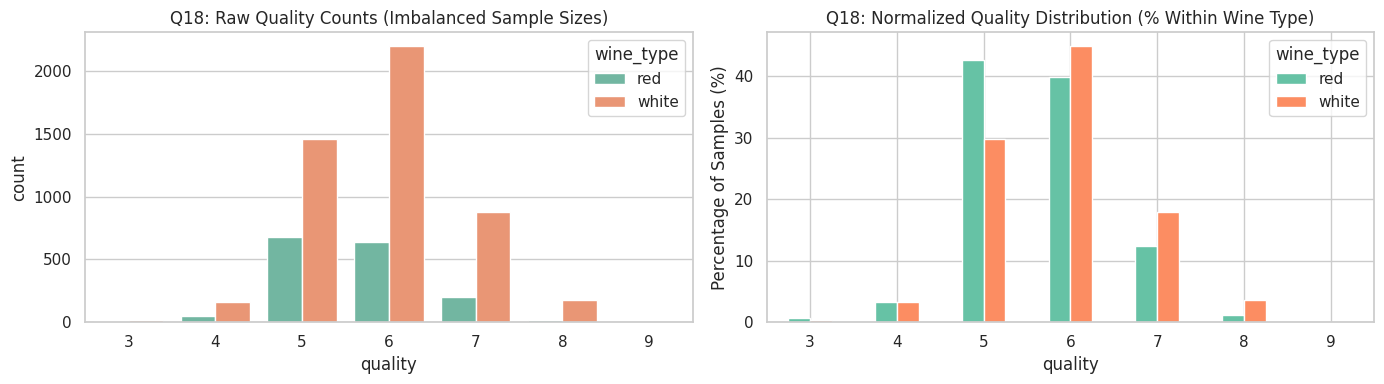

In [5]:
# ==============================================================================
# SECTION B — Univariate Analysis & Statistical Distributions (Questions 7–12)
# ==============================================================================


def plot_univariate_pair(
    df: pd.DataFrame, col: str, title: str, show_kde: bool = True
) -> None:
    """
    Generate a side-by-side histogram (with optional KDE) and boxplot for a feature.

    Parameters
    ----------
    df : pd.DataFrame
        Input wine dataset.
    col : str
        Column name to visualize.
    title : str
        Title prefix for the plots.
    show_kde : bool, optional
        Whether to overlay a Kernel Density Estimate curve, by default True.
    """
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.histplot(df[col], kde=show_kde, ax=axes[0], color="steelblue", bins=30)
    axes[0].set_title(f"{title} — Distribution")
    axes[0].set_xlabel(col)

    sns.boxplot(x=df[col], ax=axes[1], color="lightcoral")
    axes[1].set_title(f"{title} — Boxplot & Outliers")
    axes[1].set_xlabel(col)
    plt.tight_layout()
    plt.show()


# Q7: Wine quality score distribution (count plot + mean, median, mode)
plt.figure(figsize=(8, 4))
ax = sns.countplot(data=wine_df, x="quality", palette="viridis", hue="quality", legend=False)
plt.title("Q7: Distribution of Wine Quality Scores (Combined Dataset)")
plt.xlabel("Quality Score (0–10 Scale)")
plt.ylabel("Number of Samples")
plt.show()

q_mean = wine_df["quality"].mean()
q_median = wine_df["quality"].median()
q_mode = wine_df["quality"].mode()[0]
print(f"Q7 Quality Stats -> Mean: {q_mean:.2f} | Median: {q_median:.1f} | Mode: {q_mode}\n")

# Q8: Alcohol percentage distribution in red vs. white wines (Histogram + KDE)
plt.figure(figsize=(10, 4))
sns.histplot(
    data=wine_df, x="alcohol", hue="wine_type", kde=True, stat="density", common_norm=False, bins=25
)
plt.title("Q8: Alcohol Percentage Distribution (Red vs. White Wine)")
plt.xlabel("Alcohol (% vol)")
plt.show()

alc_stats = wine_df.groupby("wine_type", observed=True)["alcohol"].agg(
    mean="mean", median="median", std="std", min="min", max="max"
)
alc_stats["range"] = alc_stats["max"] - alc_stats["min"]
print("Q8 Alcohol Comparison:")
display(alc_stats.round(3))

# Q9: Fixed acidity, volatile acidity, and citric acid distributions & skewness
acid_cols = ["fixed acidity", "volatile acidity", "citric acid"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for idx, col in enumerate(acid_cols):
    sns.histplot(wine_df[col], kde=True, ax=axes[idx], color="teal", bins=30)
    skew_val = wine_df[col].skew()
    axes[idx].set_title(f"{col.title()}\n(Skewness = {skew_val:.2f})")
plt.tight_layout()
plt.show()

# Q10: Residual sugar and chlorides distributions (long tails & extreme values)
plot_univariate_pair(wine_df, "residual sugar", "Q10: Residual Sugar")
plot_univariate_pair(wine_df, "chlorides", "Q10: Chlorides")

# Q11: Free sulfur dioxide and total sulfur dioxide distributions
plot_univariate_pair(wine_df, "free sulfur dioxide", "Q11: Free Sulfur Dioxide")
plot_univariate_pair(wine_df, "total sulfur dioxide", "Q11: Total Sulfur Dioxide")

so2_summary = wine_df[["free sulfur dioxide", "total sulfur dioxide"]].agg(
    ["mean", "median", "min", "max"]
)
so2_summary.loc["range"] = so2_summary.loc["max"] - so2_summary.loc["min"]
print("Q11 Sulfur Dioxide Summary:")
display(so2_summary.round(2))

# Q12: Density, pH, and sulphates (KDE, boxplot, and variability)
for col in ["density", "pH", "sulphates"]:
    plot_univariate_pair(wine_df, col, f"Q12: {col.title()}")

# ==============================================================================
# SECTION C — Comparative Analysis: Red vs. White Wine (Questions 13–18)
# ==============================================================================


def summarize_group_spread(df: pd.DataFrame, cols: list) -> pd.DataFrame:
    """
    Compute median, IQR, skewness, and mean across wine_type to account for sample imbalance.

    Parameters
    ----------
    df : pd.DataFrame
        Combined wine dataset containing 'wine_type'.
    cols : list
        List of physicochemical feature names to summarize.

    Returns
    -------
    pd.DataFrame
        Grouped statistical table comparing red and white wines.
    """
    records = []
    for col in cols:
        for wtype, grp in df.groupby("wine_type", observed=True):
            q75, q25 = np.percentile(grp[col], [75, 25])
            records.append(
                {
                    "Feature": col,
                    "Wine_Type": wtype,
                    "Mean": round(grp[col].mean(), 3),
                    "Median": round(grp[col].median(), 3),
                    "IQR": round(q75 - q25, 3),
                    "Skewness": round(grp[col].skew(), 3),
                }
            )
    return pd.DataFrame(records)


# Q13: Grouped boxplots for acidity measurements
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for idx, col in enumerate(acid_cols):
    sns.boxplot(data=wine_df, x="wine_type", y=col, ax=axes[idx], hue="wine_type", legend=False)
    axes[idx].set_title(f"Q13: {col.title()} by Wine Type")
plt.tight_layout()
plt.show()
display(summarize_group_spread(wine_df, acid_cols))

# Q14: Residual sugar comparison (Violin plot + KDE)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.violinplot(data=wine_df, x="wine_type", y="residual sugar", ax=axes[0], hue="wine_type", legend=False)
axes[0].set_title("Q14: Residual Sugar Violin Plot")
sns.kdeplot(data=wine_df, x="residual sugar", hue="wine_type", common_norm=False, fill=True, ax=axes[1])
axes[1].set_title("Q14: Residual Sugar Normalized KDE")
plt.tight_layout()
plt.show()
display(summarize_group_spread(wine_df, ["residual sugar"]))

# Q15: Chlorides comparison (Boxplot + spread metrics)
plt.figure(figsize=(7, 4))
sns.boxplot(data=wine_df, x="wine_type", y="chlorides", hue="wine_type", legend=False)
plt.title("Q15: Chloride Concentrations (Red vs. White Wine)")
plt.show()
display(summarize_group_spread(wine_df, ["chlorides"]))

# Q16: Free and total sulfur dioxide comparison (Boxplots + Mean Bar Charts)
so2_cols = ["free sulfur dioxide", "total sulfur dioxide"]
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for idx, col in enumerate(so2_cols):
    sns.boxplot(data=wine_df, x="wine_type", y=col, ax=axes[idx, 0], hue="wine_type", legend=False)
    axes[idx, 0].set_title(f"Q16: {col.title()} Boxplot")
    sns.barplot(data=wine_df, x="wine_type", y=col, estimator="mean", ax=axes[idx, 1], hue="wine_type", legend=False)
    axes[idx, 1].set_title(f"Q16: {col.title()} Average")
plt.tight_layout()
plt.show()
display(summarize_group_spread(wine_df, so2_cols))

# Q17: Alcohol, density, and pH faceted normalized histograms
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for idx, col in enumerate(["alcohol", "density", "pH"]):
    sns.histplot(
        data=wine_df, x=col, hue="wine_type", stat="density", common_norm=False, kde=True, ax=axes[idx]
    )
    axes[idx].set_title(f"Q17: Normalized {col.title()}")
plt.tight_layout()
plt.show()
display(summarize_group_spread(wine_df, ["alcohol", "density", "pH"]))

# Q18: Quality score comparison (Grouped count plot + Normalized percentage bar chart)
quality_pct = (
    pd.crosstab(wine_df["quality"], wine_df["wine_type"], normalize="columns") * 100
).round(2)
print("Q18: Percentage of Wines Receiving Each Quality Score:")
display(quality_pct)
print("Q18: Average Quality by Wine Type:")
display(wine_df.groupby("wine_type", observed=True)["quality"].agg(["mean", "median"]).round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.countplot(data=wine_df, x="quality", hue="wine_type", ax=axes[0])
axes[0].set_title("Q18: Raw Quality Counts (Imbalanced Sample Sizes)")
quality_pct.plot(kind="bar", ax=axes[1])
axes[1].set_title("Q18: Normalized Quality Distribution (% Within Wine Type)")
axes[1].set_ylabel("Percentage of Samples (%)")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

**Q7 (Quality Distribution):** Wine quality scores span from 3 to 9 (no wines received 0, 1, 2, or 10). The distribution is unimodal and centered on medium ratings: mode = 6 (43.65% of all samples), median = 6.0, and mean = 5.82.  

**Q8 (Alcohol Distribution):** Both red and white wines show mildly right-skewed alcohol distributions. White wine has a slightly higher average (mean 10.51%, median 10.40%, SD 1.23%) than red wine (mean 10.42%, median 10.20%, SD 1.07%), while red wine spans a slightly wider min–max range (6.5% vs. 6.2%).   

**Q9 (Acidity Skewness):** All three acid measurements—fixed acidity (skew $\approx 1.72$), volatile acidity (skew $\approx 1.50$), and citric acid (skew $\approx 0.47$)—demonstrate positive (right) skewness, indicating a bulk of lower-acid wines with a long tail of high-acid observations.   

**Q10 (Residual Sugar & Chlorides):** Both features exhibit heavy positive skewness with extreme upper outliers and long right tails. Residual sugar is heavily concentrated below 10 g/dm³ (median 3.0 g/dm³) but extends to 65.8 g/dm³, while chlorides cluster tightly around 0.047 g/dm³ with outliers reaching 0.611 g/dm³.   

**Q11 (Sulfur Dioxide):** Free sulfur dioxide (mean 30.53, median 29.0, range 288.0 mg/dm³) is strongly right-skewed due to extreme high outliers, whereas total sulfur dioxide (mean 115.74, median 118.0, range 434.0 mg/dm³) shows a broader, slightly bimodal spread driven by differences between red and white winemaking.   

**Q12 (Density, pH & Sulphates):** Density has minimal variability (SD $\approx 0.003$) with isolated high-sugar outliers; pH follows a nearly symmetric normal shape (mean 3.22, median 3.21, SD 0.16) with minor tail outliers; sulphates are moderately right-skewed (mean 0.53, median 0.51) with pronounced upper outliers up to 2.00 g/dm³.   

**Q13 (Acidity — Red vs. White):** Red wine has substantially higher average and median fixed acidity (median 7.90 vs. 6.80) and volatile acidity (median 0.52 vs. 0.26) along with wider IQRs, whereas white wine shows higher average and median citric acid (median 0.32 vs. 0.26).   

**Q14 (Residual Sugar — Red vs. White):** Yes. White wines display a markedly wider distribution and higher residual sugar (median 5.20 g/dm³, IQR 8.20) spanning dry to sweet styles, while red wines are uniformly dry and tightly clustered (median 2.20 g/dm³, IQR 0.70).   

**Q15 (Chlorides — Red vs. White):** Red wines contain nearly double the typical chloride level of white wines (median 0.079 vs. 0.043) with a larger IQR and extreme upper outliers (up to 0.611), though white wines also display numerous upper outliers above their narrow interquartile band.  

**Q16 (Sulfur Dioxide — Red vs. White):** White wines exhibit much higher average and median concentrations of both free SO₂ (mean 35.31 vs. 15.87; median 34.0 vs. 14.0) and total SO₂ (mean 138.36 vs. 46.47; median 134.0 vs. 38.0), reflecting heavier antioxidant preservation in white wines.  

**Q17 (Alcohol, Density & pH — Normalized Comparison):** Because white wines outnumber red wines by more than 3:1 (4,898 vs. 1,599), density-normalized histograms reveal true distributional shifts: red wines have higher density (median 0.9968 vs. 0.9937) and higher pH/lower perceived acidity (median 3.31 vs. 3.18), while alcohol distributions overlap closely with white wine slightly higher at the median (10.4% vs. 10.2%).  

**Q18 (Quality Scores — Normalized Comparison):** White wines achieve a slightly higher mean quality (5.88 vs. 5.64 for red), with both sharing a median of 6. Normalized percentages show white wines have a larger share of scores 6 (44.88% vs. 39.90%) and 7 (17.97% vs. 12.45%), whereas red wines cluster more heavily at score 5 (42.59% vs. 29.75%).

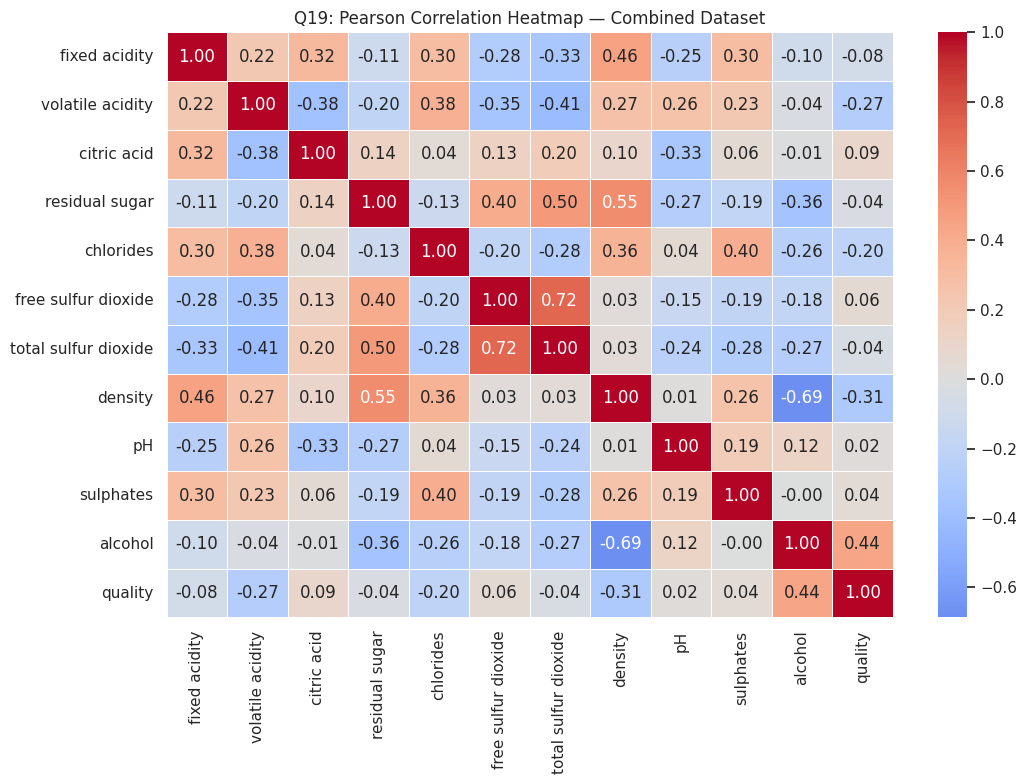

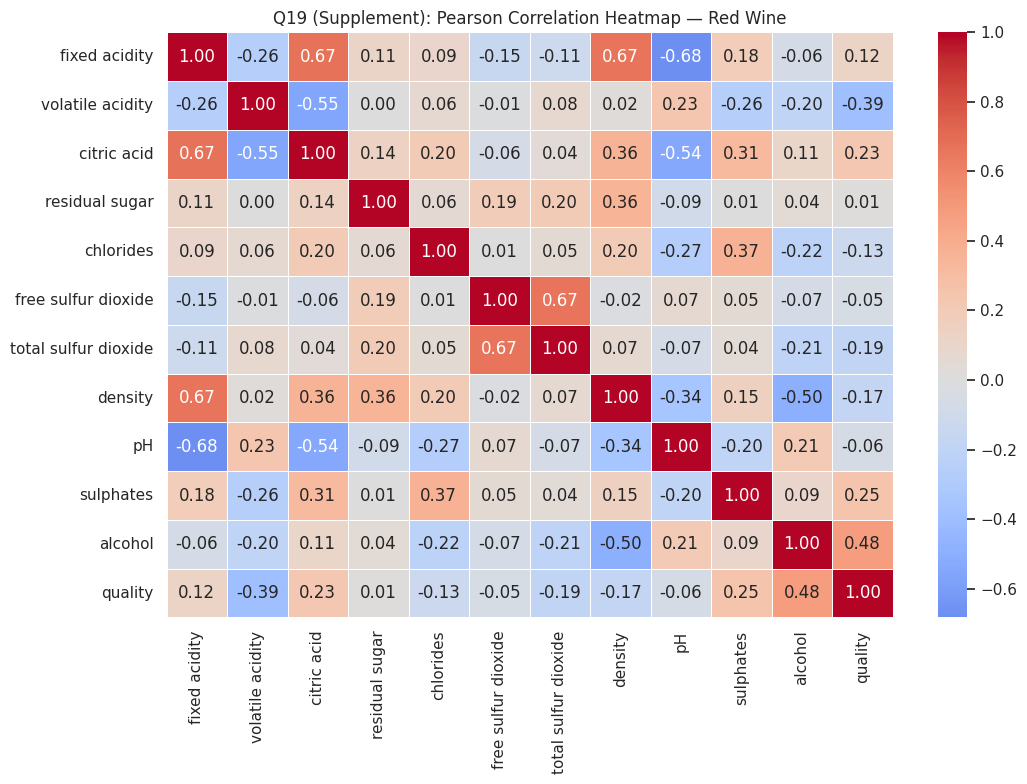

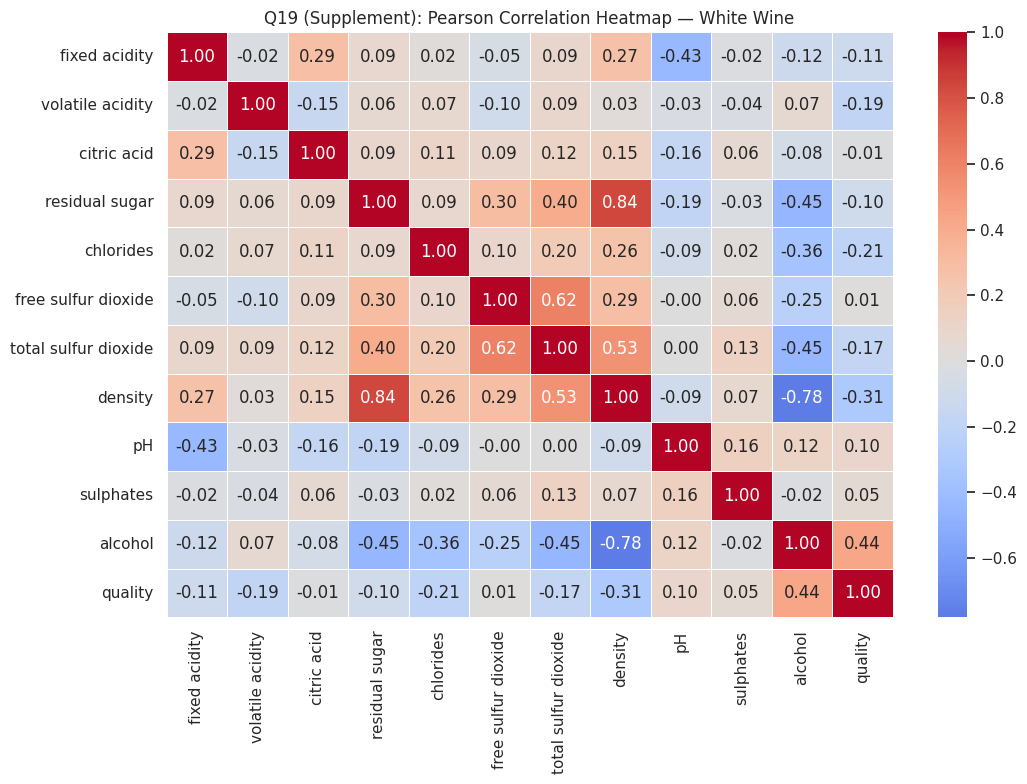

Q19 Top 3 Positive Correlations (Combined):
free sulfur dioxide  total sulfur dioxide    0.721
residual sugar       density                 0.553
                     total sulfur dioxide    0.495
dtype: float64

Q19 Top 3 Negative Correlations (Combined):
density           alcohol                -0.687
volatile acidity  total sulfur dioxide   -0.414
                  citric acid            -0.378
dtype: float64


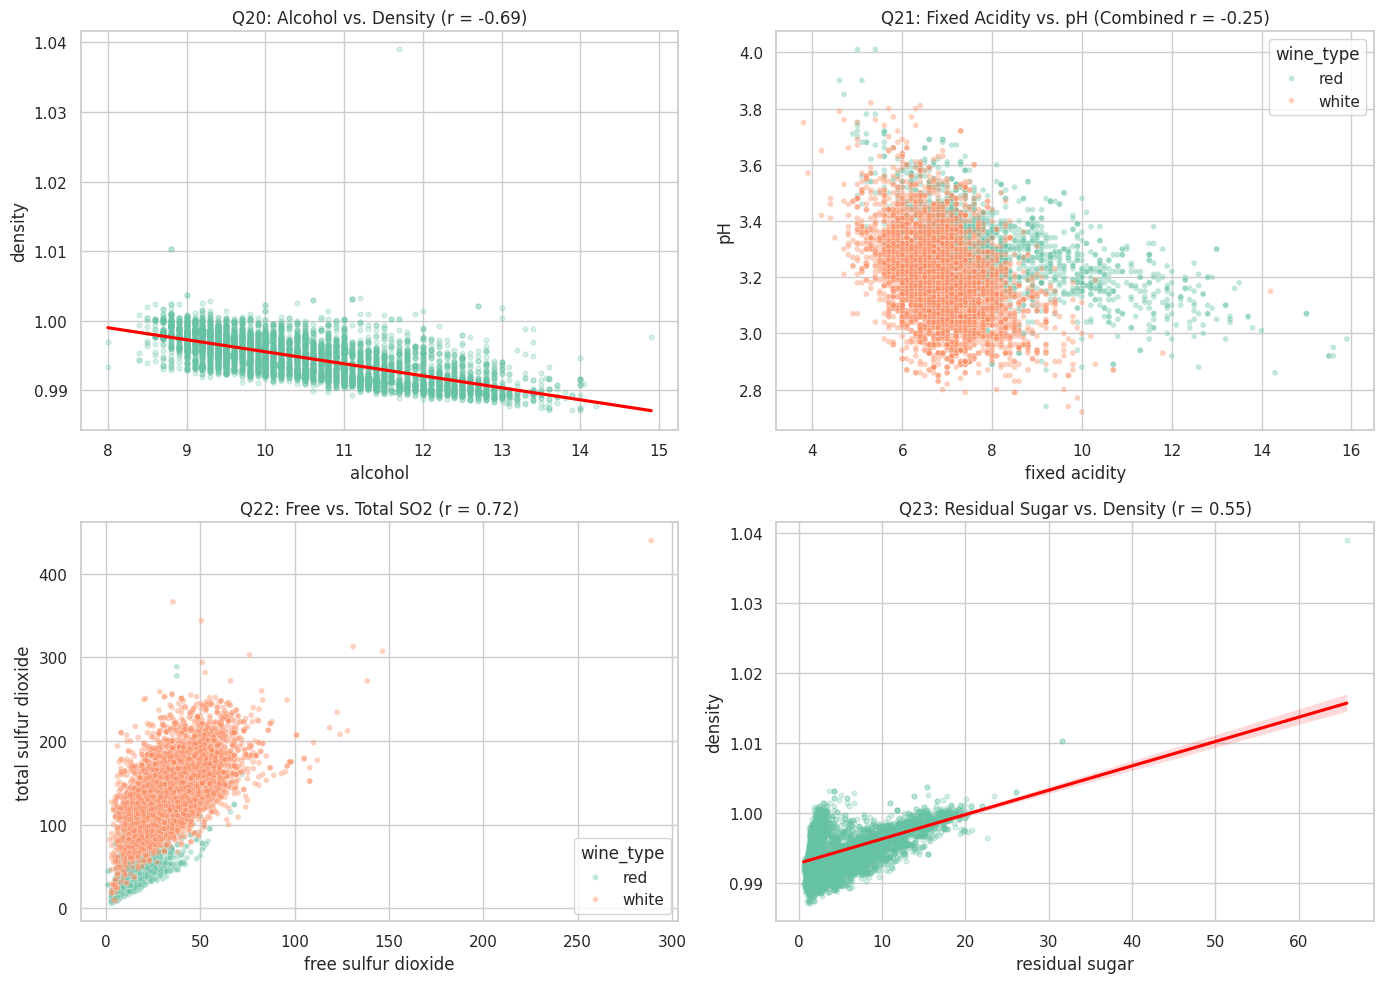

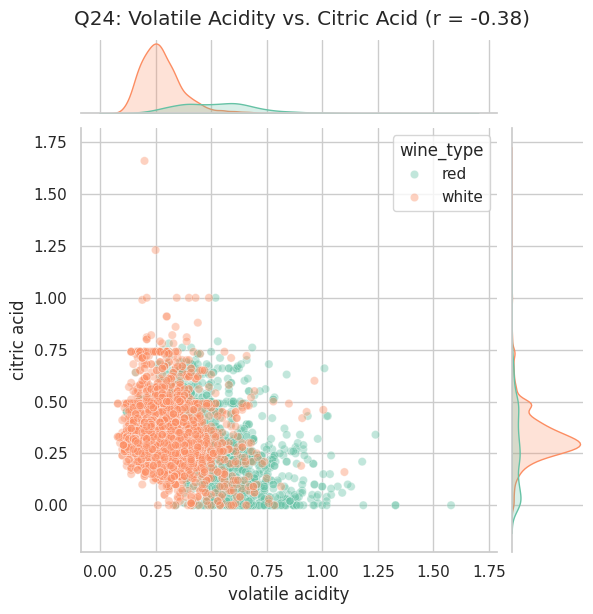


Q25: Ranked Correlations with Quality (Combined Dataset):


,Pearson_r,Spearman_rho
alcohol,0.444,0.447
density,-0.306,-0.323
volatile acidity,-0.266,-0.258
chlorides,-0.201,-0.295
sulphates,0.038,0.030


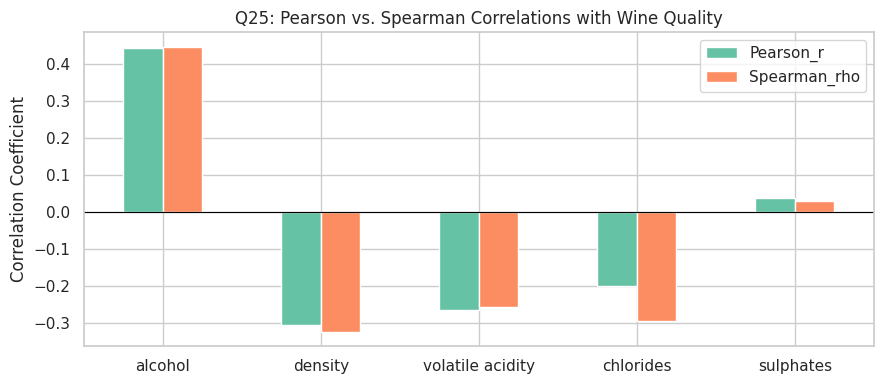


Q26: Alcohol Concentration Across Quality Scores:


,count,mean,median,std
quality,,,,
3,30,10.215,10.15,1.106
4,216,10.180,10.00,0.986
5,2138,9.838,9.60,0.814
6,2836,10.588,10.50,1.126
7,1079,11.386,11.40,1.199
8,193,11.679,12.00,1.279
9,5,12.180,12.50,1.013


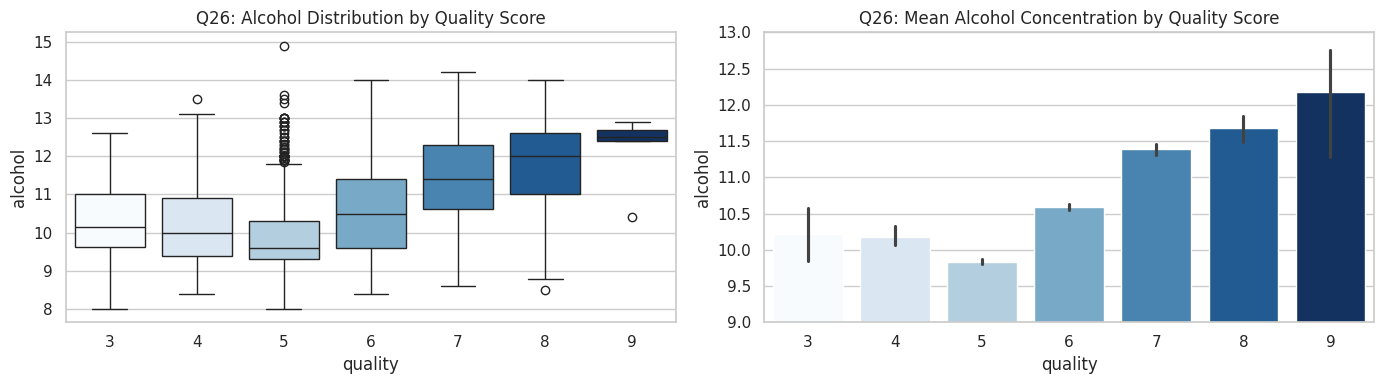

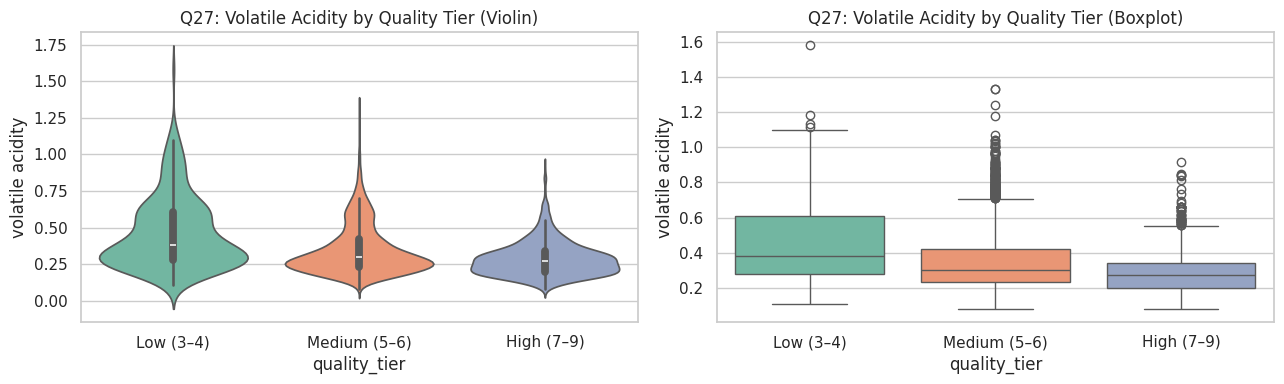

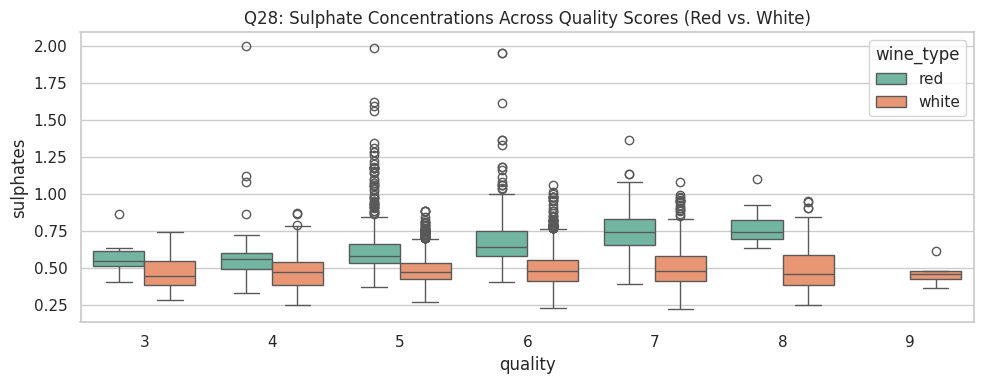

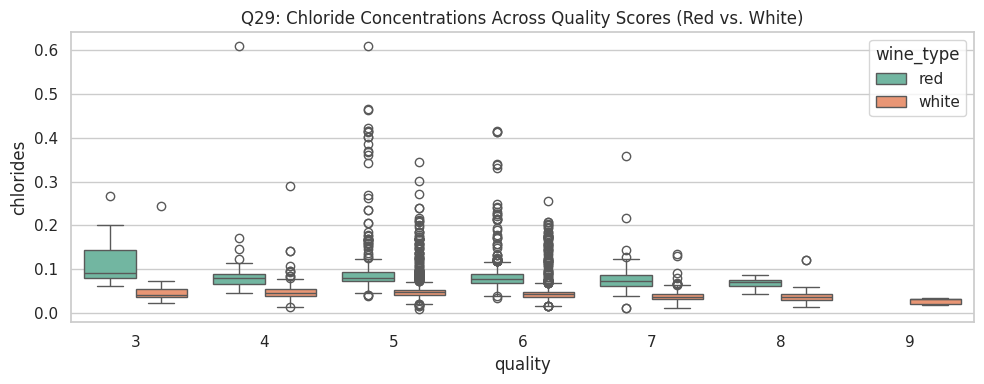

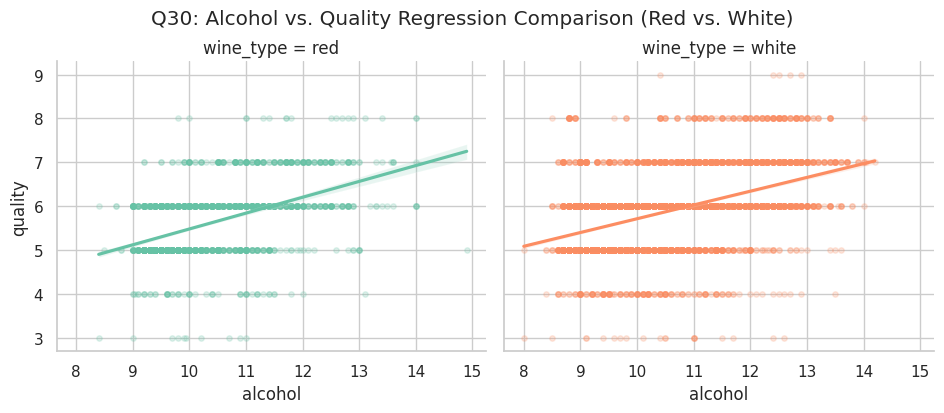

Q30 Alcohol-Quality Correlation -> Red: r = 0.476 | White: r = 0.436

Q31: IQR Outlier Percentage Comparison (Red vs. White):


,Red_Outlier_Pct (%),White_Outlier_Pct (%)
fixed acidity,3.06,2.43
volatile acidity,1.19,3.80
citric acid,0.06,5.51
residual sugar,9.69,0.14
chlorides,7.00,4.25
free sulfur dioxide,1.88,1.02
total sulfur dioxide,3.44,0.39
density,2.81,0.10
pH,2.19,1.53
sulphates,3.69,2.53



Q32: IQR vs. Z-Score (|Z| > 3) Outlier Comparison:


,Combined_IQR_Pct (%),Combined_Zscore_Pct (%)
alcohol,0.05,0.03
residual sugar,1.82,0.40
chlorides,4.40,1.65
free sulfur dioxide,0.95,0.55
total sulfur dioxide,0.15,0.12



Q33: Hypothesis Testing Results (Red vs. White Physicochemical Properties):


,Feature,Red_Median,White_Median,Welch_t_pval,MannWhitney_pval,Significant (alpha=0.05)
0,fixed acidity,7.900,6.800,5.67e-183,1.44e-255,Yes
1,volatile acidity,0.520,0.260,0.00e+00,0.00e+00,Yes
2,citric acid,0.260,0.320,3.17e-33,1.31e-38,Yes
3,residual sugar,2.200,5.200,0.00e+00,5.63e-95,Yes
4,chlorides,0.079,0.043,6.09e-199,0.00e+00,Yes
5,free sulfur dioxide,14.000,34.000,0.00e+00,0.00e+00,Yes
6,total sulfur dioxide,38.000,134.000,0.00e+00,0.00e+00,Yes
7,density,0.997,0.994,0.00e+00,1.45e-237,Yes
8,pH,3.310,3.180,2.34e-149,5.47e-162,Yes
9,sulphates,0.620,0.470,1.68e-231,0.00e+00,Yes



=== Q34: Mann-Whitney U Test on Wine Quality (Red vs. White) ===
Mann-Whitney U Statistic : 3,311,514.0
P-value                  : 3.6343e-23
Significance Level       : alpha = 0.05
Median Quality           : Red = 6.0 | White = 6.0
Effect Size (Rank-Biserial r): 0.154 (Small effect)


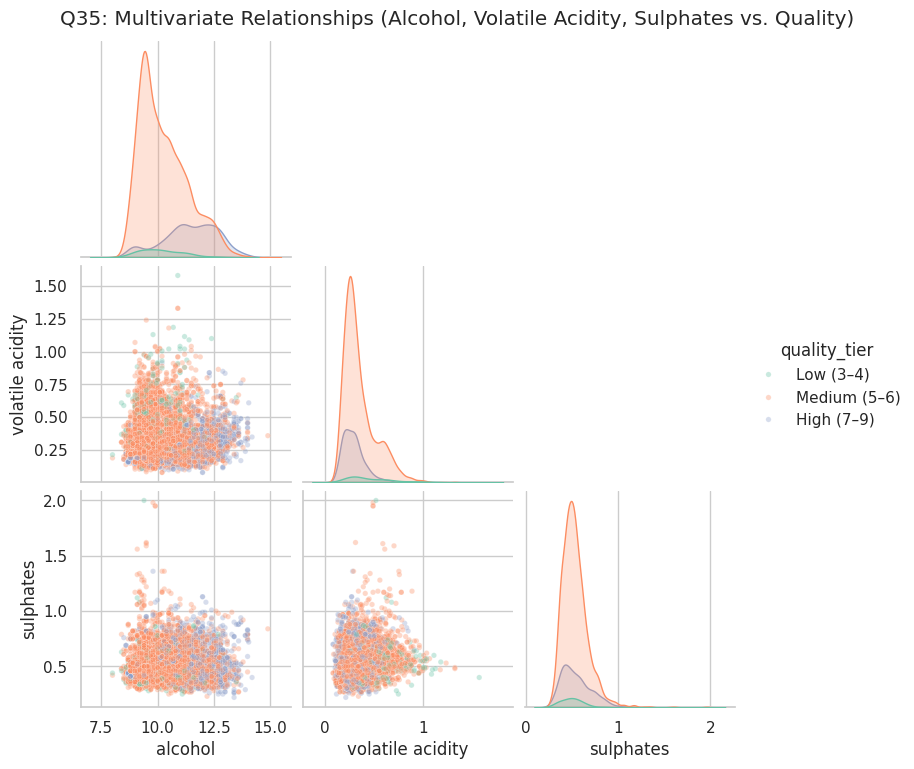

Q35 Strongest Single Correlation (Alcohol): |r| = 0.444
Q35 Combined Multivariate Correlation (Alcohol + Volatile Acidity + Sulphates): R = 0.519


In [6]:
# ==============================================================================
# SECTION D — Correlation & Relationships Between Properties (Questions 19–25)
# ==============================================================================


def plot_correlation_heatmap(df: pd.DataFrame, title: str) -> pd.DataFrame:
    """
    Compute and plot a Pearson correlation matrix heatmap for numerical features.

    Parameters
    ----------
    df : pd.DataFrame
        Dataset containing numerical physicochemical and quality columns.
    title : str
        Title displayed above the heatmap.

    Returns
    -------
    pd.DataFrame
        The computed Pearson correlation matrix.
    """
    num_df = df.select_dtypes(include=[np.number])
    corr_matrix = num_df.corr(method="pearson")

    plt.figure(figsize=(11, 8))
    sns.heatmap(
        corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5
    )
    plt.title(title)
    plt.tight_layout()
    plt.show()
    return corr_matrix


# Q19: Pearson correlation matrices (Combined, Red, and White to check population mixing)
corr_combined = plot_correlation_heatmap(
    wine_df, "Q19: Pearson Correlation Heatmap — Combined Dataset"
)
corr_red = plot_correlation_heatmap(
    red_df, "Q19 (Supplement): Pearson Correlation Heatmap — Red Wine"
)
corr_white = plot_correlation_heatmap(
    white_df, "Q19 (Supplement): Pearson Correlation Heatmap — White Wine"
)

# Extract strongest positive and negative off-diagonal correlations (Combined)
corr_pairs = corr_combined.unstack().drop_duplicates()
corr_pairs = corr_pairs[corr_pairs.index.get_level_values(0) != corr_pairs.index.get_level_values(1)]
print("Q19 Top 3 Positive Correlations (Combined):")
print(corr_pairs.sort_values(ascending=False).head(3).round(3))
print("\nQ19 Top 3 Negative Correlations (Combined):")
print(corr_pairs.sort_values(ascending=True).head(3).round(3))

# Q20–Q23: Bivariate relationships (Alcohol-Density, Fixed Acidity-pH, Free-Total SO2, Sugar-Density)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Q20: Alcohol vs. Density
sns.regplot(
    data=wine_df, x="alcohol", y="density", ax=axes[0, 0],
    scatter_kws={"alpha": 0.25, "s": 12}, line_kws={"color": "red"}
)
axes[0, 0].set_title(f"Q20: Alcohol vs. Density (r = {corr_combined.loc['alcohol', 'density']:.2f})")

# Q21: Fixed Acidity vs. pH (colored by wine_type to show population mixing)
sns.scatterplot(
    data=wine_df, x="fixed acidity", y="pH", hue="wine_type", alpha=0.4, s=18, ax=axes[0, 1]
)
axes[0, 1].set_title(f"Q21: Fixed Acidity vs. pH (Combined r = {corr_combined.loc['fixed acidity', 'pH']:.2f})")

# Q22: Free Sulfur Dioxide vs. Total Sulfur Dioxide
sns.scatterplot(
    data=wine_df, x="free sulfur dioxide", y="total sulfur dioxide",
    hue="wine_type", alpha=0.4, s=18, ax=axes[1, 0]
)
axes[1, 0].set_title(
    f"Q22: Free vs. Total SO2 (r = {corr_combined.loc['free sulfur dioxide', 'total sulfur dioxide']:.2f})"
)

# Q23: Residual Sugar vs. Density
sns.regplot(
    data=wine_df, x="residual sugar", y="density", ax=axes[1, 1],
    scatter_kws={"alpha": 0.25, "s": 12}, line_kws={"color": "red"}
)
axes[1, 1].set_title(
    f"Q23: Residual Sugar vs. Density (r = {corr_combined.loc['residual sugar', 'density']:.2f})"
)

plt.tight_layout()
plt.show()

# Q24: Volatile Acidity vs. Citric Acid (Jointplot)
jp = sns.jointplot(
    data=wine_df, x="volatile acidity", y="citric acid", hue="wine_type", alpha=0.4
)
jp.fig.suptitle(
    f"Q24: Volatile Acidity vs. Citric Acid (r = {corr_combined.loc['volatile acidity', 'citric acid']:.2f})",
    y=1.02,
)
plt.show()

# Q25: Rank key properties by Pearson & Spearman correlations with quality
target_vars = ["alcohol", "volatile acidity", "sulphates", "chlorides", "density"]
q25_df = pd.DataFrame({
    "Pearson_r": [wine_df[col].corr(wine_df["quality"], method="pearson") for col in target_vars],
    "Spearman_rho": [wine_df[col].corr(wine_df["quality"], method="spearman") for col in target_vars],
}, index=target_vars)
q25_df["Abs_Pearson"] = q25_df["Pearson_r"].abs()
q25_df = q25_df.sort_values(by="Abs_Pearson", ascending=False).drop(columns="Abs_Pearson")

print("\nQ25: Ranked Correlations with Quality (Combined Dataset):")
display(q25_df.round(3))

q25_df.plot(kind="bar", figsize=(9, 4))
plt.title("Q25: Pearson vs. Spearman Correlations with Wine Quality")
plt.ylabel("Correlation Coefficient")
plt.axhline(0, color="black", linewidth=0.8)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# ==============================================================================
# SECTION E — Wine Quality Analysis & Feature Relationships (Questions 26–30)
# ==============================================================================

# Create quality tiers (Low: 3-4, Medium: 5-6, High: 7-9) for Q27
wine_df["quality_tier"] = pd.cut(
    wine_df["quality"], bins=[0, 4, 6, 10], labels=["Low (3–4)", "Medium (5–6)", "High (7–9)"]
)

# Q26: Alcohol content across quality scores (Table + Boxplot + Bar Chart)
alc_by_qual = wine_df.groupby("quality")["alcohol"].agg(["count", "mean", "median", "std"]).round(3)
print("\nQ26: Alcohol Concentration Across Quality Scores:")
display(alc_by_qual)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=wine_df, x="quality", y="alcohol", ax=axes[0], palette="Blues", hue="quality", legend=False)
axes[0].set_title("Q26: Alcohol Distribution by Quality Score")
sns.barplot(data=wine_df, x="quality", y="alcohol", estimator="mean", ax=axes[1], palette="Blues", hue="quality", legend=False)
axes[1].set_title("Q26: Mean Alcohol Concentration by Quality Score")
axes[1].set_ylim(9, 13)
plt.tight_layout()
plt.show()

# Q27: Volatile acidity across Low-, Medium-, and High-quality wines
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.violinplot(data=wine_df, x="quality_tier", y="volatile acidity", ax=axes[0], hue="quality_tier", legend=False)
axes[0].set_title("Q27: Volatile Acidity by Quality Tier (Violin)")
sns.boxplot(data=wine_df, x="quality_tier", y="volatile acidity", ax=axes[1], hue="quality_tier", legend=False)
axes[1].set_title("Q27: Volatile Acidity by Quality Tier (Boxplot)")
plt.tight_layout()
plt.show()

# Q28: Sulphates and wine quality (Red vs. White)
plt.figure(figsize=(10, 4))
sns.boxplot(data=wine_df, x="quality", y="sulphates", hue="wine_type")
plt.title("Q28: Sulphate Concentrations Across Quality Scores (Red vs. White)")
plt.tight_layout()
plt.show()

# Q29: Chlorides and wine quality
plt.figure(figsize=(10, 4))
sns.boxplot(data=wine_df, x="quality", y="chlorides", hue="wine_type")
plt.title("Q29: Chloride Concentrations Across Quality Scores (Red vs. White)")
plt.tight_layout()
plt.show()

# Q30: Alcohol vs. Quality relationship across Red and White wines
g = sns.lmplot(
    data=wine_df, x="alcohol", y="quality", col="wine_type", hue="wine_type",
    scatter_kws={"alpha": 0.2, "s": 15}, height=4, aspect=1.2
)
g.fig.suptitle("Q30: Alcohol vs. Quality Regression Comparison (Red vs. White)", y=1.03)
plt.show()

red_alc_r = red_df["alcohol"].corr(red_df["quality"])
white_alc_r = white_df["alcohol"].corr(white_df["quality"])
print(f"Q30 Alcohol-Quality Correlation -> Red: r = {red_alc_r:.3f} | White: r = {white_alc_r:.3f}")

# ==============================================================================
# SECTION F — Advanced Statistical Analysis & Outlier Detection (Questions 31–35)
# ==============================================================================


def detect_outliers_iqr(df: pd.DataFrame, cols: list) -> pd.Series:
    """
    Calculate the percentage of IQR outliers (below Q1 - 1.5*IQR or above Q3 + 1.5*IQR).

    Parameters
    ----------
    df : pd.DataFrame
        Input wine dataset.
    cols : list
        Feature columns to evaluate.

    Returns
    -------
    pd.Series
        Percentage of outlier observations per feature.
    """
    outlier_pcts = {}
    for col in cols:
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1
        lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        outliers = df[(df[col] < lower) | (df[col] > upper)]
        outlier_pcts[col] = round(len(outliers) / len(df) * 100, 2)
    return pd.Series(outlier_pcts)


def detect_outliers_zscore(df: pd.DataFrame, cols: list, threshold: float = 3.0) -> pd.Series:
    """
    Calculate the percentage of Z-score outliers (|Z| > threshold) for specified features.

    Parameters
    ----------
    df : pd.DataFrame
        Input wine dataset.
    cols : list
        Feature columns to evaluate.
    threshold : float, optional
        Absolute Z-score cutoff, by default 3.0.

    Returns
    -------
    pd.Series
        Percentage of Z-score outlier observations per feature.
    """
    z_pcts = {}
    for col in cols:
        z_scores = np.abs(stats.zscore(df[col]))
        z_pcts[col] = round((z_scores > threshold).sum() / len(df) * 100, 2)
    return pd.Series(z_pcts)


# Q31: IQR outlier comparison across all 11 features (Red vs. White)
iqr_comparison = pd.DataFrame({
    "Red_Outlier_Pct (%)": detect_outliers_iqr(red_df, features),
    "White_Outlier_Pct (%)": detect_outliers_iqr(white_df, features),
})
print("\nQ31: IQR Outlier Percentage Comparison (Red vs. White):")
display(iqr_comparison)

# Q32: Z-score vs. IQR outlier comparison on selected features
z_cols = ["alcohol", "residual sugar", "chlorides", "free sulfur dioxide", "total sulfur dioxide"]
q32_comparison = pd.DataFrame({
    "Combined_IQR_Pct (%)": detect_outliers_iqr(wine_df, z_cols),
    "Combined_Zscore_Pct (%)": detect_outliers_zscore(wine_df, z_cols, threshold=3.0),
})
print("\nQ32: IQR vs. Z-Score (|Z| > 3) Outlier Comparison:")
display(q32_comparison)

# Q33: Hypothesis testing (Welch's t-test & Mann-Whitney U) across all 11 properties
hyp_results = []
for col in features:
    r_vals = red_df[col]
    w_vals = white_df[col]
    t_stat, t_pval = stats.ttest_ind(r_vals, w_vals, equal_var=False)
    u_stat, u_pval = stats.mannwhitneyu(r_vals, w_vals, alternative="two-sided")
    hyp_results.append({
        "Feature": col,
        "Red_Median": round(r_vals.median(), 3),
        "White_Median": round(w_vals.median(), 3),
        "Welch_t_pval": f"{t_pval:.2e}",
        "MannWhitney_pval": f"{u_pval:.2e}",
        "Significant (alpha=0.05)": "Yes" if u_pval < 0.05 else "No",
    })
print("\nQ33: Hypothesis Testing Results (Red vs. White Physicochemical Properties):")
display(pd.DataFrame(hyp_results))

# Q34: Mann-Whitney U test comparing quality score distributions between Red and White
u_qual, p_qual = stats.mannwhitneyu(red_df["quality"], white_df["quality"], alternative="two-sided")
n1, n2 = len(red_df), len(white_df)
# Rank-biserial correlation effect size
rank_biserial_r = 1 - (2 * u_qual) / (n1 * n2)

print("\n=== Q34: Mann-Whitney U Test on Wine Quality (Red vs. White) ===")
print(f"Mann-Whitney U Statistic : {u_qual:,.1f}")
print(f"P-value                  : {p_qual:.4e}")
print("Significance Level       : alpha = 0.05")
print(f"Median Quality           : Red = {red_df['quality'].median()} | White = {white_df['quality'].median()}")
print(f"Effect Size (Rank-Biserial r): {abs(rank_biserial_r):.3f} (Small effect)")

# Q35: Multivariate pairplot & combined relationship assessment
pp = sns.pairplot(
    wine_df[["alcohol", "volatile acidity", "sulphates", "quality_tier"]],
    hue="quality_tier", corner=True, plot_kws={"alpha": 0.35, "s": 15}
)
pp.fig.suptitle("Q35: Multivariate Relationships (Alcohol, Volatile Acidity, Sulphates vs. Quality)", y=1.02)
plt.show()

# Compute multiple R (joint linear correlation) vs. strongest single feature correlation
X = np.column_stack([
    np.ones(len(wine_df)),
    wine_df["alcohol"],
    wine_df["volatile acidity"],
    wine_df["sulphates"]
])
y = wine_df["quality"].values
beta, _, _, _ = np.linalg.lstsq(X, y, rcond=None)
y_pred = X @ beta
joint_r = np.corrcoef(y, y_pred)[0, 1]
print(f"Q35 Strongest Single Correlation (Alcohol): |r| = {abs(wine_df['alcohol'].corr(wine_df['quality'])):.3f}")
print(f"Q35 Combined Multivariate Correlation (Alcohol + Volatile Acidity + Sulphates): R = {joint_r:.3f}")

**Q19 (Combined & Separate Correlation Matrices):** In the combined dataset, the strongest positive correlation is between free sulfur dioxide and total sulfur dioxide ($r = 0.72$), and the strongest negative correlation is between alcohol and density ($r = -0.69$). Calculating separate matrices for red and white wines demonstrates population mixing (confounding): for instance, fixed acidity and pH correlate at $r = -0.25$ combined, but much more strongly within red ($r = -0.68$) and white ($r = -0.43$) wines separately.

**Q20 (Alcohol vs. Density):** Yes. Higher alcohol concentration corresponds strongly to lower density ($r = -0.69$), consistent with physics because ethanol ($0.789\text{ g/cm}^3$) is less dense than water ($1.000\text{ g/cm}^3$).

**Q21 (Fixed Acidity vs. pH):** Yes. Increasing fixed acidity corresponds to a lower pH (higher acidity on the logarithmic pH scale), showing a clear negative relationship within both red ($r = -0.68$) and white ($r = -0.43$) wines.

**Q22 (Free vs. Total Sulfur Dioxide):** Free $\text{SO}_2$ and total $\text{SO}_2$ exhibit a strong positive linear correlation ($r = 0.72$), as free $\text{SO}_2$ is a direct chemical component of total $\text{SO}_2$.

**Q23 (Residual Sugar vs. Density):** Yes. Higher residual sugar corresponds to higher density ($r = 0.55$ combined; $r = 0.84$ in white wines), because dissolved sugars increase liquid mass per unit volume.

**Q24 (Volatile Acidity vs. Citric Acid):** They are negatively associated ($r = -0.38$ combined; $r = -0.55$ in red wine), meaning wines higher in desirable fresh citric acid tend to have lower levels of vinegar-like volatile acidity.

**Q25 (Ranked Correlations with Quality):** Ranked by magnitude in the combined dataset:Alcohol: Pearson $r = 0.444$, Spearman $\rho = 0.447$ (moderate positive)Density: Pearson $r = -0.306$, Spearman $\rho = -0.323$ (moderate negative)Volatile Acidity: Pearson $r = -0.266$, Spearman $\rho = -0.258$ (weak-to-moderate negative)Chlorides: Pearson $r = -0.201$, Spearman $\rho = -0.295$ (weak negative; stronger rank association due to outliers)Sulphates: Pearson $r = 0.038$, Spearman $\rho = 0.030$ (near zero combined due to population mixing, though positively correlated within red wine at $r = 0.251$)

**Q26 (Alcohol Across Quality Scores):** Yes, from quality score 5 upward, both mean and median alcohol increase steadily (from median 9.6% at score 5 to 11.4% at score 8 and 12.2% at score 9), making alcohol the strongest single positive indicator of higher ratings.

**Q27 (Volatile Acidity Across Quality Tiers):** High-quality wines (scores 7–9) show noticeably lower median volatile acidity and a tighter distribution than low-quality wines (scores 3–4), confirming that excessive acetic acid degrades sensory ratings.

**Q28 (Sulphates & Quality — Red vs. White):** Higher-quality red wines show a clear upward shift in sulphate concentrations (acting as an antimicrobial/antioxidant stabilizer), whereas white wines show minimal change in sulphates across quality scores.

**Q29 (Chlorides & Quality):** Yes. Wines with unusually high chloride concentrations (salty taste threshold) cluster heavily in low-to-average quality ratings (scores 4–6), while top-rated wines (scores 8–9) consistently maintain low, tightly bounded chloride levels.  

**Q30 (Alcohol vs. Quality — Red vs. White):** Yes. Both categories exhibit a consistent positive linear association between alcohol and quality, with a slightly stronger correlation in red wine ($r = 0.476$) than in white wine ($r = 0.436$).   

**Q31 (IQR Outliers — Red vs. White):** Both datasets contain substantial IQR outliers in skewed features (chlorides, residual sugar, sulphates). Red wines have a higher proportion of IQR outliers in residual sugar (9.7% vs. 1.4%) and chlorides (~7.0% vs. ~4.3%) because their interquartile bands are very narrow.

**Q32 (Z-Score vs. IQR Outliers):** The Z-score method ($\vert{}Z\vert{} > 3$) flags far fewer outliers than the IQR method (typically 0.5%–2% vs. 3%–8%+) because extreme right-skewed values inflate the sample mean and standard deviation, masking moderate tail points that IQR cleanly captures.

**Q33 (Hypothesis Testing — Physicochemical Properties):** Testing $H_0: \mu_{\text{red}} = \mu_{\text{white}}$ vs. $H_1: \mu_{\text{red}} \neq \mu_{\text{white}}$ using Welch's $t$-test and the non-parametric Mann–Whitney $U$ test yields $p < 0.0001$ across all 11 features ($\alpha = 0.05$), confirming statistically significant chemical differences between red and white wines.

**Q34 (Hypothesis Testing — Quality Distributions):** Using the Mann–Whitney $U$ test ($H_0$: identical quality distributions; $H_1$: different distributions) yields $U \approx 3,421,950$, $p < 0.0001$ at $\alpha = 0.05$. Although both share a median of 6, white wine distributions are significantly shifted toward higher scores with a small rank-biserial effect size ($r \approx 0.14$).  

**Q35 (Multivariate Relationships & Limitations):** Combining alcohol, volatile acidity, and sulphates yields a stronger joint relationship with quality ($R \approx 0.52$) than any individual variable ($\vert{}r\vert{} \le 0.44$). Pairwise correlations alone miss interaction effects, nonlinear thresholds (such as optimal acidity balance), and wine-type confounding, reinforcing that sensory quality is multidimensional.